# code_219 · Compression must earn its resource and quality claims

**Book:** section 41.4. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_41_GUIDE.md), [execution evidence](../CHAPTER_41_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_219).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Deployment contracts bind source-fitted transformations, model state, schema and version. Resource measurements are actual observations of this run, separated from deterministic scientific results; no production service or autonomous engineering clearance is claimed. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8019;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
Darwin arm64 CPU; seed 8019


## Construct four explicit alternatives to one trained teacher
 Generate1,200 source examples with four standardized measurements and a nonlinear binary response whose probability increases with the first load coordinate. Train a4–32–16–1 teacher with two tanh hidden layers for350 full-batch Adam steps. On copied parameters, prune the smallest60 percent of matrix entries; separately quantize each matrix symmetrically to stored int8 plus one scale and retain floating biases; separately factor the middle matrix at rank4 by SVD. Int8 is a storage encoding here: evaluation dequantizes and uses floating operations. Pruning retains dense zero arrays rather than a sparse kernel. Low-rank evaluation actually multiplies through the two factors. Train a4–8–1 student for400 steps with half observed-label BCE and half soft teacher-probability BCE. All budgets and choices are fixed before600 independent final labels are generated. This is a declared original distillation mechanism, not a full reproduction of Deep Compression or its hardware claims.


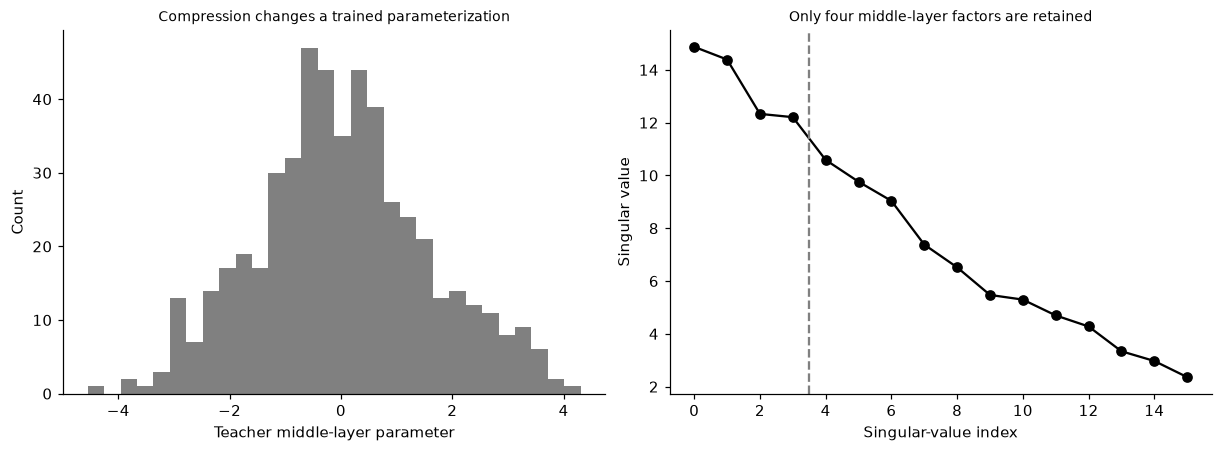

In [2]:
import hashlib
xs=rng.normal(size=(1200,4));true=lambda x:expit(1.2*x[:,0]-.7*x[:,1]+.6*np.sin(x[:,2])+.25*x[:,1]*x[:,3]);ys=rng.binomial(1,true(xs));xt=torch.tensor(xs);yt=torch.tensor(ys,dtype=torch.float64)[:,None];teacher=nn.Sequential(nn.Linear(4,32),nn.Tanh(),nn.Linear(32,16),nn.Tanh(),nn.Linear(16,1));optimizer=torch.optim.Adam(teacher.parameters(),lr=.015)
for _ in range(350):
    optimizer.zero_grad();loss=nn.functional.binary_cross_entropy_with_logits(teacher(xt),yt);loss.backward();optimizer.step()
teacher.eval();pruned=copy.deepcopy(teacher);quantized=[]
with torch.no_grad():
    for layer in pruned:
        if isinstance(layer,nn.Linear):threshold=torch.quantile(layer.weight.abs(),.6);layer.weight[layer.weight.abs()<=threshold]=0
for layer in teacher:
    if isinstance(layer,nn.Linear):
        w=layer.weight.detach().numpy();scale=float(np.max(abs(w))/127);q=np.rint(w/scale).astype(np.int8);quantized.append((q,scale,layer.bias.detach().numpy().copy()))
def quant_predict(x):
    z=x
    for j,(q,scale,bias) in enumerate(quantized):
        z=z@(q.astype(float)*scale).T+bias
        if j<2:z=np.tanh(z)
    return expit(z[:,0])
weights=[layer for layer in teacher if isinstance(layer,nn.Linear)];middle=weights[1].weight.detach().numpy();u,s,vh=np.linalg.svd(middle,full_matrices=False);left=u[:,:4]*s[:4];right=vh[:4]
def lowrank_predict(x):
    z=np.tanh(x@weights[0].weight.detach().numpy().T+weights[0].bias.detach().numpy());z=np.tanh((z@right.T)@left.T+weights[1].bias.detach().numpy());return expit((z@weights[2].weight.detach().numpy().T+weights[2].bias.detach().numpy())[:,0])
student=nn.Sequential(nn.Linear(4,8),nn.Tanh(),nn.Linear(8,1));optimizer=torch.optim.Adam(student.parameters(),lr=.02);soft=torch.sigmoid(teacher(xt)).detach()
for _ in range(400):
    optimizer.zero_grad();logits=student(xt);loss=.5*nn.functional.binary_cross_entropy_with_logits(logits,yt)+.5*nn.functional.binary_cross_entropy_with_logits(logits,soft);loss.backward();optimizer.step()
student.eval();xf=rng.normal(size=(600,4));yf=rng.binomial(1,true(xf))
def torch_predict(m,x):
    with torch.no_grad():return torch.sigmoid(m(torch.tensor(x))).numpy()[:,0]
predictors={'Teacher':lambda x:torch_predict(teacher,x),'Dense pruned':lambda x:torch_predict(pruned,x),'Int8 storage':quant_predict,'Rank4':lowrank_predict,'Student':lambda x:torch_predict(student,x)};predictions={name:fn(xf) for name,fn in predictors.items()};assert all(np.all(np.isfinite(v)) and np.all((v>=0)&(v<=1)) for v in predictions.values());assert sum(torch.count_nonzero(layer.weight).item() for layer in pruned if isinstance(layer,nn.Linear))<sum(layer.weight.numel() for layer in pruned if isinstance(layer,nn.Linear));assert left.shape==(16,4) and right.shape==(4,32);assert all(q.dtype==np.int8 for q,scale,bias in quantized);RESULTS.update(source_rows=1200,independent_final_rows=600,teacher_steps=350,student_steps=400,student_objective='half observed BCE plus half teacher soft-probability BCE',pruning_fraction=.6,lowrank_middle_rank=4,int8_is_storage_not_integer_kernel=True,pruned_arrays_remain_dense=True);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].hist(teacher[2].weight.detach().numpy().ravel(),bins=30,color='.5');axes[0].set(xlabel='Teacher middle-layer parameter',ylabel='Count',title='Compression changes a trained parameterization');axes[1].plot(s,'o-',color='black');axes[1].axvline(3.5,color='.5',linestyle='--');axes[1].set(xlabel='Singular-value index',ylabel='Singular value',title='Only four middle-layer factors are retained');plt.show()


## Check slices and calibration before interpreting an efficiency frontier
 Evaluate independent overall and rare high-load outcomes; the rare slice is x0>1.5 and is fixed in advance. Brier, clipped log loss, ten fixed-bin calibration error and threshold disagreement with the teacher describe different behaviours. A positive load perturbation tests a known monotonic tendency of this generated law; violations reveal a model check rather than a general physics certificate. Probability bounds alone establish neither calibration nor structural equilibrium. Count numeric parameter-storage bytes with the stated encoding; int8 dequantization requires floating temporary buffers and this count is not resident memory. Time the actual implemented forward functions after warm-up for30 repetitions on the same256 final feature rows, keeping timings outside deterministic results. VisualB plots each measured local implementation against quality and stored bytes; retain slower or worse variants. No final score selects a release.


,model,Brier,rare_Brier,log_loss,ECE_ten_fixed_bins,teacher_decision_disagreement,load_monotonicity_violations,stored_numeric_parameter_bytes
0,Teacher,0.281905,0.163826,1.103835,0.245511,0.000000,209,5640
1,Dense pruned,0.499188,0.865905,3.294199,0.481770,0.565000,385,5640
2,Int8 storage,0.281617,0.164639,1.102579,0.242594,0.003333,213,1072
3,Rank4,0.298219,0.142737,1.566759,0.269392,0.326667,181,3080
4,Student,0.198375,0.090121,0.583949,0.031354,0.250000,0,392


,model,batch_rows,repetitions,median_seconds,p95_seconds
0,Teacher,256,30,0.000084,0.000086
1,Dense pruned,256,30,0.000084,0.000086
2,Int8 storage,256,30,0.000046,0.000050
3,Rank4,256,30,0.000050,0.000053
4,Student,256,30,0.000024,0.000032


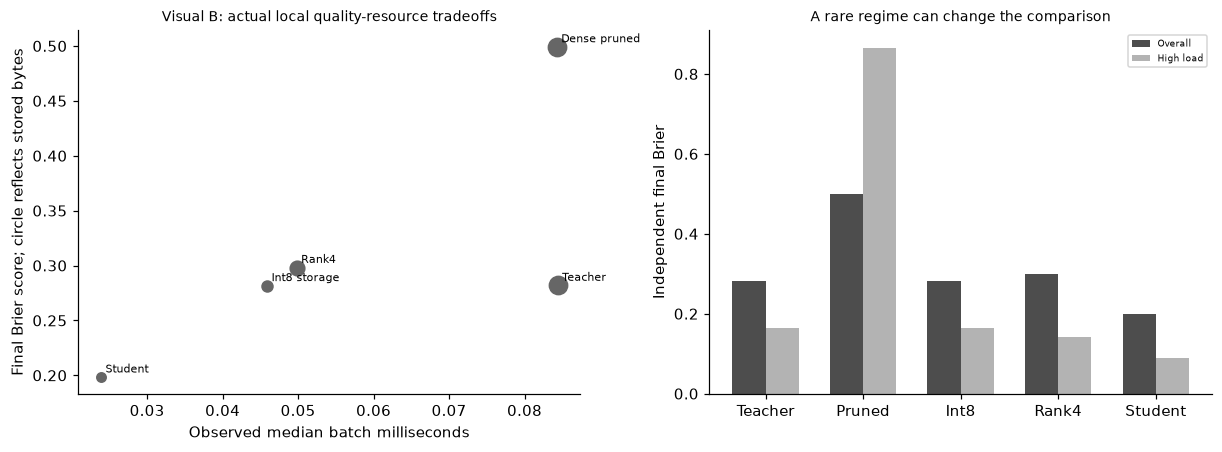

In [3]:
rare=xf[:,0]>1.5;assert rare.sum()>10
def ece(p,y):
    bins=np.minimum((p*10).astype(int),9);return float(sum(np.sum(bins==j)/len(y)*abs(p[bins==j].mean()-y[bins==j].mean()) for j in range(10) if np.any(bins==j)))
sizes={'Teacher':sum(p.numel()*p.element_size() for p in teacher.parameters()),'Dense pruned':sum(p.numel()*p.element_size() for p in pruned.parameters()),'Int8 storage':sum(q.nbytes+8+b.nbytes for q,scale,b in quantized),'Rank4':sum(p.numel()*p.element_size() for p in teacher.parameters())-middle.nbytes+left.nbytes+right.nbytes,'Student':sum(p.numel()*p.element_size() for p in student.parameters())};rows=[];MEASUREMENTS={'forward_latency':[]};changed=xf.copy();changed[:,0]+=.1
for name,fn in predictors.items():
    p=predictions[name];pc=np.clip(p,1e-12,1-1e-12);row={'model':name,'Brier':float(np.mean((p-yf)**2)),'rare_Brier':float(np.mean((p[rare]-yf[rare])**2)),'log_loss':float(-np.mean(yf*np.log(pc)+(1-yf)*np.log(1-pc))),'ECE_ten_fixed_bins':ece(p,yf),'teacher_decision_disagreement':float(np.mean((p>=.5)!=(predictions['Teacher']>=.5))),'load_monotonicity_violations':int(np.sum(fn(changed)<p-1e-10)),'stored_numeric_parameter_bytes':int(sizes[name])};rows.append(row);fn(xf[:256]);durations=[]
    for _ in range(30):
        t=time.perf_counter();fn(xf[:256]);durations.append(time.perf_counter()-t)
    MEASUREMENTS['forward_latency'].append({'model':name,'batch_rows':256,'repetitions':30,'median_seconds':float(np.median(durations)),'p95_seconds':float(np.quantile(durations,.95))})
RESULTS.update(rare_high_load_rows=int(rare.sum()),quality_profiles=rows,prediction_sha256={name:hashlib.sha256(p.tobytes()).hexdigest() for name,p in predictions.items()},quality_does_not_select_release=True);display(pd.DataFrame(rows));display(pd.DataFrame(MEASUREMENTS['forward_latency']));fig,axes=plt.subplots(1,2,figsize=(11,4))
for row,resource in zip(rows,MEASUREMENTS['forward_latency']):
    axes[0].scatter(resource['median_seconds']*1000,row['Brier'],s=30+row['stored_numeric_parameter_bytes']/50,color='.4');axes[0].annotate(row['model'],(resource['median_seconds']*1000,row['Brier']),fontsize=7,xytext=(3,3),textcoords='offset points')
axes[0].set(xlabel='Observed median batch milliseconds',ylabel='Final Brier score; circle reflects stored bytes',title='Visual B: actual local quality-resource tradeoffs');axes[1].bar(np.arange(5)-.17,[r['Brier'] for r in rows],width=.34,label='Overall',color='.3');axes[1].bar(np.arange(5)+.17,[r['rare_Brier'] for r in rows],width=.34,label='High load',color='.7');axes[1].set(xticks=range(5),xticklabels=['Teacher','Pruned','Int8','Rank4','Student'],ylabel='Independent final Brier',title='A rare regime can change the comparison');axes[1].legend(fontsize=6);plt.show()


In [4]:
summary={'example_id':'code_219','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual own-model teacher and soft-target distilled student training', 'magnitude pruning symmetric int8 storage with floating dequantization and factored low-rank forward pass', 'independent overall rare-slice calibration probability and monotonicity checks', 'actual observed latency numeric-storage quality frontier without sparse or integer runtime claims'],'results':RESULTS,'resource_measurements':globals().get('MEASUREMENTS',{}),'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual own-model teacher and soft-target distilled student training", "magnitude pruning symmetric int8 storage with floating dequantization and factored low-rank forward pass", "independent overall rare-slice calibration probability and monotonicity checks", "actual observed latency numeric-storage quality frontier without sparse or integer runtime claims"], "elapsed_seconds": 1.567, "example_id": "code_219", "hardware": "Darwin arm64 CPU", "resource_measurements": {"forward_latency": [{"batch_rows": 256, "median_seconds": 8.437500218860805e-05, "model": "Teacher", "p95_seconds": 8.625188929727301e-05, "repetitions": 30}, {"batch_rows": 256, "median_seconds": 8.425000123679638e-05, "model": "Dense pruned", "p95_seconds": 8.591003861511127e-05, "repetitions": 30}, {"batch_rows": 256, "median_seconds": 4.587500006891787e-05, "model": "Int8 storage", "p95_seconds": 5.001248646294698e-05, "repetitions": 30}, {"batch_rows": 256, "median_se